<a href="https://colab.research.google.com/github/aureliearth/Analisis-Deret-Waktu/blob/main/ADW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Perbandingan Performa Metode ARIMA dan Holt-Winters dalam Peramalan Gross Quantity Penjualan Harian Produk Rambut

## Latar Belakang


*   Motivasi: Peramalan membantu memperkirakan jumlah produk yang perlu disediakan pada periode mendatang.
*   Masalah: Perubahan jumlah produk yang terjual setiap hari dapat menimbulkan ketidakpastian dalam menentukan kebutuhan stok.
* Tujuan: Membandingkan performa ARIMA dan Holt-Winters dalam meramalkan gross quantity penjualan harian produk rambut.


## Data dan Karakteristik
* Data: Penjualan Produk Rambut
* Periode: Maret-Juni 2026
* Frekuensi: Harian
* Observasi: 122 hari
* Total gross quantity: 95.504 unit
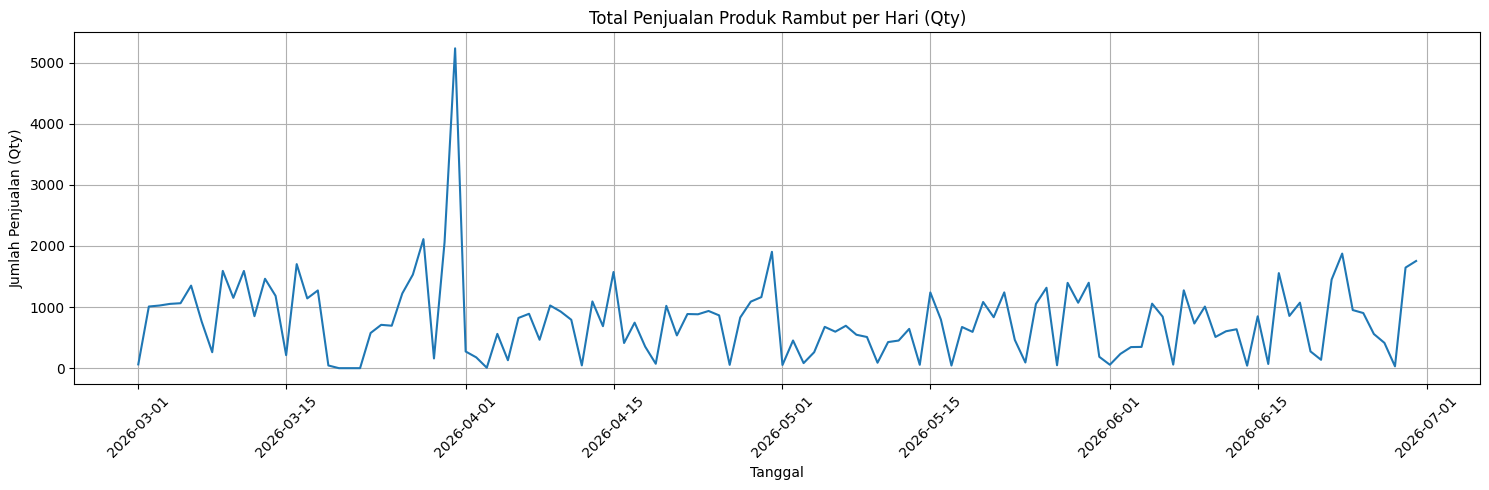



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.stattools import adfuller

In [ ]:
# Extracting the file ID from the provided Google Drive link
file_id = '1jgPeLoVV8ZrYG4hn-fnZ2muDDCmDpBsT'

# Using the export URL for Google Sheets/Excel stored on Drive
url = f'https://docs.google.com/spreadsheets/d/{file_id}/export?format=xlsx'

try:
    df = pd.read_excel(url)
    print("Dataset loaded successfully!")
    display(df.head())
except Exception as e:
    print("Error loading dataset. Please make sure the file is shared as 'Anyone with the link can view'.")
    print(e)

Dataset loaded successfully!


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
0,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,8010101021*,Color Chart Zillenial Colour System New ( 5 po...,ShowMeMore,1,750000,750000,0,0,750000
1,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,6,109000,654000,0,0,654000
2,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,12,116000,1392000,0,0,1392000
3,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1050202011,SLEEK ET LISSE Step 1 Strong Curly Hair 500 Ml,Straight System,3,159000,477000,0,0,477000
4,2026-03-01,ACC-SINV-2026-05723,ZIZE SALON - MEDAN,MDN,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,1,116000,116000,0,0,116000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34563 entries, 0 to 34562
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Tanggal        34562 non-null  datetime64[ns]
 1   Sales Invoice  34562 non-null  object        
 2   Customer       34562 non-null  object        
 3   Branch         34562 non-null  object        
 4   Item Code      34562 non-null  object        
 5   Item Name      34562 non-null  object        
 6   Sub Brand      34562 non-null  object        
 7   Qty            34563 non-null  int64         
 8   Harga          34563 non-null  int64         
 9   Total Harga    34563 non-null  int64         
 10  Retur          34563 non-null  int64         
 11  Diskon         34563 non-null  int64         
 12  Total          34563 non-null  int64         
dtypes: datetime64[ns](1), int64(6), object(6)
memory usage: 3.4+ MB


In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34563 entries, 0 to 34562
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Tanggal        34562 non-null  datetime64[ns]
 1   Sales Invoice  34562 non-null  object        
 2   Customer       34562 non-null  object        
 3   Branch         34562 non-null  object        
 4   Item Code      34562 non-null  object        
 5   Item Name      34562 non-null  object        
 6   Sub Brand      34562 non-null  object        
 7   Qty            34563 non-null  int64         
 8   Harga          34563 non-null  int64         
 9   Total Harga    34563 non-null  int64         
 10  Retur          34563 non-null  int64         
 11  Diskon         34563 non-null  int64         
 12  Total          34563 non-null  int64         
dtypes: datetime64[ns](1), int64(6), object(6)
memory usage: 3.4+ MB


,Tanggal,Qty,Harga,Total Harga,Retur,Diskon,Total
count,34562,34563.000000,3.456300e+04,3.456300e+04,3.456300e+04,3.456300e+04,3.456300e+04
mean,2026-04-28 05:00:01.458248704,5.538466,3.805443e+05,9.090358e+05,2.632060e+03,2.004585e+04,8.863579e+05
min,2026-03-01 00:00:00,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-2.900000e+06
25%,2026-03-28 00:00:00,1.000000,1.035000e+05,1.160000e+05,0.000000e+00,0.000000e+00,1.160000e+05
50%,2026-04-25 00:00:00,1.000000,1.250000e+05,2.100000e+05,0.000000e+00,0.000000e+00,2.090000e+05
75%,2026-05-30 00:00:00,3.000000,1.800000e+05,4.360000e+05,0.000000e+00,0.000000e+00,4.260000e+05
max,2026-06-30 00:00:00,95713.000000,6.576376e+09,1.570950e+10,4.548595e+07,3.464224e+08,1.531759e+10
std,NaN,514.838581,3.537451e+07,8.450676e+07,2.476581e+05,1.865345e+06,8.239885e+07


In [ ]:
# Hapus baris yang tidak memiliki tanggal
df = df.dropna(subset=["Tanggal"]).copy()

# Ubah kolom tanggal menjadi datetime
df["Tanggal"] = pd.to_datetime(
    df["Tanggal"],
    errors="coerce"
)

# Hapus tanggal yang gagal dikonversi
df = df.dropna(subset=["Tanggal"])

# Ubah Qty menjadi numerik
df["Qty"] = pd.to_numeric(
    df["Qty"],
    errors="coerce"
)

# Hapus transaksi dengan Qty tidak valid
df = df.dropna(subset=["Qty"])

# Periksa apakah kolom 'Sales Invoice' masih ada sebelum memisahkan retur
if "Sales Invoice" in df.columns:
    # Identifikasi jenis invoice
    df["Jenis_Invoice"] = np.where(
        df["Sales Invoice"].astype(str).str.contains(
            "RET",
            case=False,
            na=False
        ),
        "Invoice Retur",
        "Invoice Penjualan"
    )

    # Tampilkan jumlah transaksi
    print("Jumlah transaksi sebelum pemisahan:")
    display(df["Jenis_Invoice"].value_counts())

    # Pisahkan transaksi penjualan (tanpa retur)
    df = df[
        df["Jenis_Invoice"] == "Invoice Penjualan"
    ].copy()
else:
    print("Peringatan: Kolom 'Sales Invoice' tidak ditemukan karena kolom bertipe 'object' telah dihapus sebelumnya.")
    print("Pembersihan retur diabaikan.")

# Hilangkan komponen jam jika ada
df["Tanggal"] = df["Tanggal"].dt.normalize()

print("Ukuran data saat ini:", df.shape)
print("Total Qty penjualan:", df["Qty"].sum())

Jumlah transaksi sebelum pemisahan:


,count
Jenis_Invoice,
Invoice Penjualan,34392
Invoice Retur,170


Ukuran data saat ini: (34392, 14)
Total Qty penjualan: 95504


In [ ]:
# Jumlahkan Qty penjualan berdasarkan tanggal
data_harian = (
    df.groupby("Tanggal")["Qty"]
    .sum()
    .reset_index()
)

# Urutkan berdasarkan tanggal
data_harian = data_harian.sort_values("Tanggal")

# Tampilkan hasil
display(data_harian.head(10))

print("Jumlah observasi:", len(data_harian))
print("Total Qty penjualan:", data_harian["Qty"].sum())

,Tanggal,Qty
0,2026-03-01,62
1,2026-03-02,1009
2,2026-03-03,1025
3,2026-03-04,1052
4,2026-03-05,1063
5,2026-03-06,1351
6,2026-03-07,763
7,2026-03-08,261
8,2026-03-09,1592
9,2026-03-10,1151


Jumlah observasi: 119
Total Qty penjualan: 95504


In [ ]:
# Buat rentang tanggal harian lengkap
tanggal_lengkap = pd.date_range(
    start=data_harian["Tanggal"].min(),
    end=data_harian["Tanggal"].max(),
    freq="D"
)

# Jadikan tanggal sebagai index
data_harian = (
    data_harian
    .set_index("Tanggal")
    .reindex(tanggal_lengkap, fill_value=0)
)

# Beri nama index dan kolom
data_harian.index.name = "Tanggal"
data_harian.columns = ["Qty"]

# Tampilkan hasil
display(data_harian.head(15))

print("Jumlah observasi harian:", len(data_harian))

,Qty
Tanggal,
2026-03-01,62
2026-03-02,1009
2026-03-03,1025
2026-03-04,1052
2026-03-05,1063
2026-03-06,1351
2026-03-07,763
2026-03-08,261
2026-03-09,1592


Jumlah observasi harian: 122


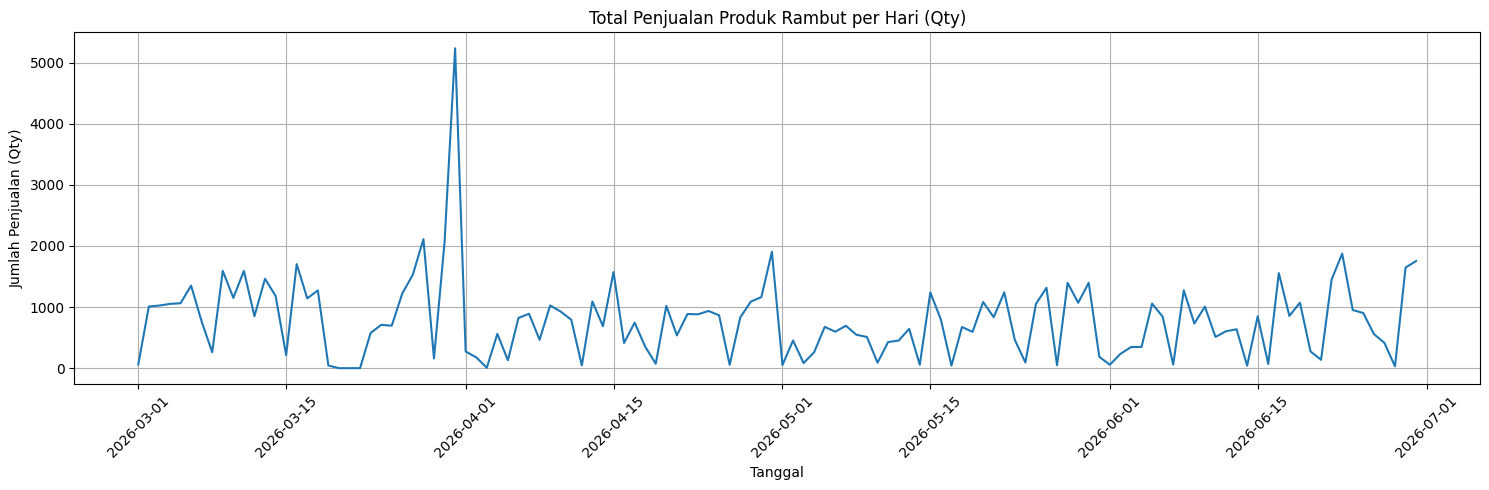

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    data_harian.index,
    data_harian["Qty"]
)

plt.title("Total Penjualan Produk Rambut per Hari (Qty)")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan (Qty)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss

# Convert to a 1D series to prevent shape alignment errors in KPSS
series_data = data_harian["Qty"]

hasil_adf = adfuller(series_data, autolag='AIC')

print("ADF Statistic:", hasil_adf[0])
print("p-value:", hasil_adf[1])
if hasil_adf[1] < 0.05:
    print("\nKesimpulan: Data STASIONER (ADF)")
else:
    print("\nKesimpulan: Data BELUM STASIONER (ADF)")

hasil_kpss = kpss(series_data, regression='c', nlags='auto')

print("\nKPSS Statistic:", hasil_kpss[0])
print("p-value:", hasil_kpss[1])
if hasil_kpss[1] < 0.05:
    print("\nKesimpulan: Data TIDAK STASIONER (KPSS)")
else:
    print("\nKesimpulan: Data STASIONER (KPSS)")

ADF Statistic: -9.415814419451188
p-value: 5.673470255621003e-16

Kesimpulan: Data STASIONER (ADF)

KPSS Statistic: 0.2157780113183211
p-value: 0.1

Kesimpulan: Data STASIONER (KPSS)


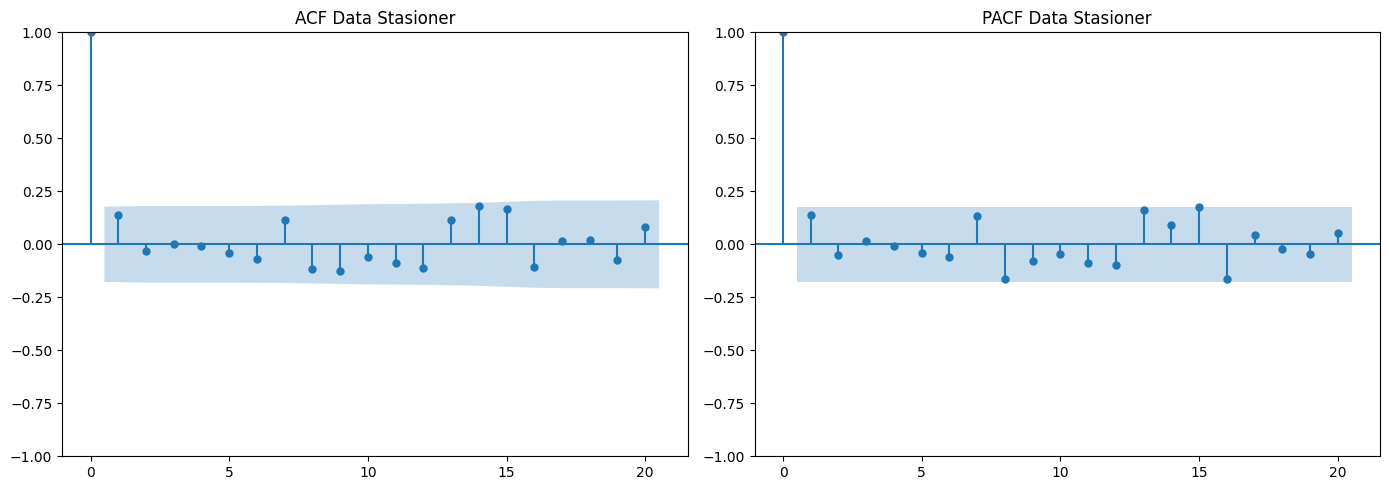

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, ax = plt.subplots(1, 2, figsize=(14,5))

plot_acf(data_harian["Qty"], lags=20, ax=ax[0])
ax[0].set_title("ACF Data Gross Qty")

plot_pacf(data_harian["Qty"], lags=20, ax=ax[1], method='ywm')
ax[1].set_title("PACF Data Gross Qty")

plt.tight_layout()
plt.show()

In [ ]:

from statsmodels.tsa.arima.model import ARIMA

# Membagi data training sebesar 80%
batas_train = int(len(data_harian) * 0.8)
train = data_harian["Qty"].iloc[:batas_train]
test = data_harian["Qty"].iloc[batas_train:]

# Kandidat model ARIMA
models = {
    "ARIMA(0,0,0)": (0, 0, 0),
    "ARIMA(1,0,0)": (1, 0, 0),
    "ARIMA(0,0,1)": (0, 0, 1),
    "ARIMA(1,0,1)": (1, 0, 1),
    "ARIMA(2,0,0)": (2, 0, 0),
    "ARIMA(0,0,2)": (0, 0, 2),
    "ARIMA(2,0,1)": (2, 0, 1),
    "ARIMA(1,0,2)": (1, 0, 2),
    "ARIMA(2,0,2)": (2, 0, 2)
}

hasil_evaluasi = []

for nama, orde in models.items():
    try:
        model = ARIMA(
            train,
            order=orde,
            trend="c"
        )
        hasil = model.fit()

        hasil_evaluasi.append({
            "Model": nama,
            "AIC": round(hasil.aic, 2),
            "BIC": round(hasil.bic, 2)
        })

    except Exception as e:
        print(f"{nama} gagal: {e}")

df_hasil = pd.DataFrame(hasil_evaluasi)

df_hasil = df_hasil.sort_values(
    "AIC"
).reset_index(drop=True)

display(df_hasil)

,Model,AIC,BIC
0,"ARIMA(1,0,1)",1545.68,1555.98
1,"ARIMA(0,0,1)",1546.27,1554.00
2,"ARIMA(1,0,0)",1546.41,1554.14
3,"ARIMA(0,0,0)",1546.78,1551.93
4,"ARIMA(2,0,1)",1547.13,1560.00
5,"ARIMA(1,0,2)",1547.17,1560.04
6,"ARIMA(2,0,0)",1548.28,1558.58
7,"ARIMA(0,0,2)",1548.32,1558.62
8,"ARIMA(2,0,2)",1549.18,1564.63


In [ ]:
hasil_aic = df_hasil.sort_values("AIC")

print("Urutan berdasarkan AIC:")
print(hasil_aic)

hasil_bic = df_hasil.sort_values("BIC")

print("\nUrutan berdasarkan BIC:")
print(hasil_bic)

model_aic = df_hasil.loc[df_hasil["AIC"].idxmin()]
model_bic = df_hasil.loc[df_hasil["BIC"].idxmin()]

print("\nModel dengan AIC terkecil:")
print(model_aic)

print("\nModel dengan BIC terkecil:")
print(model_bic)

Urutan berdasarkan AIC:
          Model      AIC      BIC
0  ARIMA(1,0,1)  1545.68  1555.98
1  ARIMA(0,0,1)  1546.27  1554.00
2  ARIMA(1,0,0)  1546.41  1554.14
3  ARIMA(0,0,0)  1546.78  1551.93
4  ARIMA(2,0,1)  1547.13  1560.00
5  ARIMA(1,0,2)  1547.17  1560.04
6  ARIMA(2,0,0)  1548.28  1558.58
7  ARIMA(0,0,2)  1548.32  1558.62
8  ARIMA(2,0,2)  1549.18  1564.63

Urutan berdasarkan BIC:
          Model      AIC      BIC
3  ARIMA(0,0,0)  1546.78  1551.93
1  ARIMA(0,0,1)  1546.27  1554.00
2  ARIMA(1,0,0)  1546.41  1554.14
0  ARIMA(1,0,1)  1545.68  1555.98
6  ARIMA(2,0,0)  1548.28  1558.58
7  ARIMA(0,0,2)  1548.32  1558.62
4  ARIMA(2,0,1)  1547.13  1560.00
5  ARIMA(1,0,2)  1547.17  1560.04
8  ARIMA(2,0,2)  1549.18  1564.63

Model dengan AIC terkecil:
Model    ARIMA(1,0,1)
AIC           1545.68
BIC           1555.98
Name: 0, dtype: object

Model dengan BIC terkecil:
Model    ARIMA(0,0,0)
AIC           1546.78
BIC           1551.93
Name: 3, dtype: object


In [ ]:
best_model_aic = model_aic["Model"]
best_model_bic = model_bic["Model"]

print("Model terbaik berdasarkan AIC:", best_model_aic)
print("Model terbaik berdasarkan BIC:", best_model_bic)

Model terbaik berdasarkan AIC: ARIMA(1,0,1)
Model terbaik berdasarkan BIC: ARIMA(0,0,0)


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# Memodelkan dua kandidat terbaik
model_arima_101 = ARIMA(
    train,
    order=(1, 0, 1),
    trend="c"
).fit()

model_arima_000 = ARIMA(
    train,
    order=(0, 0, 0),
    trend="c"
).fit()

# Menyimpan model
model_arima = {
    "ARIMA(1,0,1)": model_arima_101,
    "ARIMA(0,0,0)": model_arima_000
}

print("Ringkasan Model ARIMA(1,0,1)")
print(model_arima_101.summary())

print("\nRingkasan Model ARIMA(0,0,0)")
print(model_arima_000.summary())

Ringkasan Model ARIMA(1,0,1)
                               SARIMAX Results                                
Dep. Variable:                    Qty   No. Observations:                   97
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -768.839
Date:                Sat, 14 Nov 2026   AIC                           1545.677
Time:                        07:00:03   BIC                           1555.976
Sample:                    03-01-2026   HQIC                          1549.842
                         - 06-05-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        778.0063     94.740      8.212      0.000     592.319     963.693
ar.L1         -0.8184      0.156     -5.241      0.000      -1.125      -0.512
ma.L1          0.9645  

# Uji Residual

Rata-rata residual: 1.476549


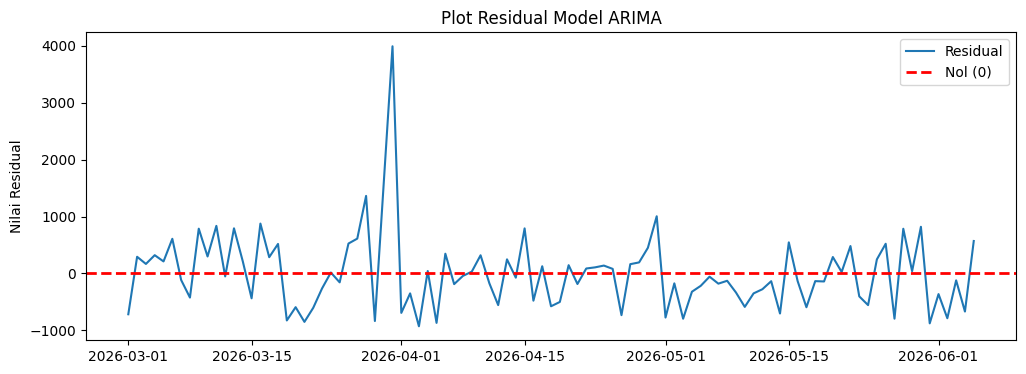

In [ ]:
# Ekstrak residual dari hasil model terbaik (ARIMA 1,0,1)
residual = hasil_best_model.resid

mean_residual = residual.mean()
print(f"Rata-rata residual: {mean_residual:.6f}")

# Plot residual untuk visualisasi
plt.figure(figsize=(12, 4))
plt.plot(residual, label='Residual')
plt.axhline(0, color='red', linestyle='--', linewidth=2, label='Nol (0)')
plt.title("Plot Residual Model ARIMA")
plt.ylabel("Nilai Residual")
plt.legend()
plt.show()

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Melakukan uji Ljung-Box pada lag 10 dan 20
ljung_box_result = acorr_ljungbox(residual, lags=[10, 20], return_df=True)

print("Hasil Uji Ljung-Box:")
display(ljung_box_result)

# Menampilkan kesimpulan uji Ljung-Box berdasarkan p-value
significance_level = 0.05

print("\nKESIMPULAN UJI LJUNG-BOX:")
for lag, row in ljung_box_result.iterrows():
    p_val = row['lb_pvalue']
    print(f"Lag {lag}: P-value = {p_val:.4f}")
    if p_val < significance_level:
        print(f"Tolak H0: Terdapat gejala autokorelasi pada residual di lag {lag}.\n")
    else:
        print(f"Gagal Tolak H0: Tidak terdapat gejala autokorelasi pada residual di lag {lag} (Residual bersifat independent/White Noise).\n")

Hasil Uji Ljung-Box:


,lb_stat,lb_pvalue
10,5.311274,0.869439
20,21.169404,0.387223



KESIMPULAN UJI LJUNG-BOX:
Lag 10: P-value = 0.8694
Gagal Tolak H0: Tidak terdapat gejala autokorelasi pada residual di lag 10 (Residual bersifat independent/White Noise).

Lag 20: P-value = 0.3872
Gagal Tolak H0: Tidak terdapat gejala autokorelasi pada residual di lag 20 (Residual bersifat independent/White Noise).



HASIL UJI JARQUE-BERA:
Statistik Jarque-Bera : 583.6425
P-value               : 0.0000
Kesimpulan: P-value < 0.05, Residual TIDAK berdistribusi normal.\n


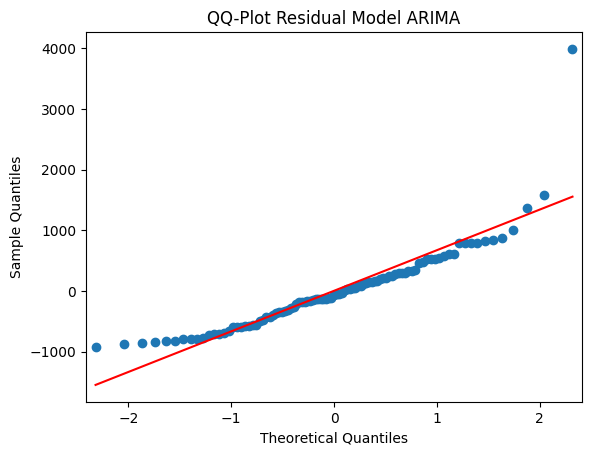

In [ ]:
import statsmodels.api as sm
import scipy.stats as stats

# 1. Uji Statistik Jarque-Bera
jb_stat, jb_pvalue = stats.jarque_bera(residual)
print("HASIL UJI JARQUE-BERA:")
print(f"Statistik Jarque-Bera : {jb_stat:.4f}")
print(f"P-value               : {jb_pvalue:.4f}")
if jb_pvalue < 0.05:
    print("Kesimpulan: P-value < 0.05, Residual TIDAK berdistribusi normal.\\n")
else:
    print("Kesimpulan: P-value >= 0.05, Residual berdistribusi normal.\\n")

# 2. Visualisasi dengan QQ-Plot
fig = sm.qqplot(residual, line='s')
plt.title("QQ-Plot Residual Model ARIMA")
plt.show()

# Prediksi

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# ==========================================
# 1. Prediksi ARIMA(1,0,1) - berdasarkan AIC
# ==========================================
pred_arima_101 = model_arima_101.forecast(steps=len(test))
pred_arima_101.index = test.index

# ==========================================
# 2. Prediksi ARIMA(0,0,0) - berdasarkan BIC
# ==========================================
pred_arima_000 = model_arima_000.forecast(steps=len(test))
pred_arima_000.index = test.index

# ==========================================
# 3. Prediksi Holt-Winters
# ==========================================
model_hw = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

fit_hw = model_hw.fit(optimized=True)

pred_hw = fit_hw.forecast(steps=len(test))
pred_hw.index = test.index

# Menggabungkan hasil prediksi
hasil_prediksi = pd.DataFrame({
    "Aktual": test,
    "ARIMA(1,0,1)": pred_arima_101,
    "ARIMA(0,0,0)": pred_arima_000,
    "Holt-Winters": pred_hw
})

# Prediksi Qty tidak boleh negatif
hasil_prediksi.iloc[:, 1:] = hasil_prediksi.iloc[:, 1:].clip(lower=0)

display(hasil_prediksi.round(2))

,Aktual,"ARIMA(1,0,1)","ARIMA(0,0,0)",Holt-Winters
Tanggal,,,,
2026-06-06,843,1100.92,777.36,387.52
2026-06-07,58,513.73,777.36,0.00
2026-06-08,1274,994.30,777.36,654.77
2026-06-09,731,600.99,777.36,920.59
2026-06-10,1008,922.88,777.36,444.82
2026-06-11,511,659.44,777.36,321.55
2026-06-12,604,875.05,777.36,456.47
2026-06-13,637,698.59,777.36,329.90
2026-06-14,41,843.01,777.36,0.00


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluasi_model(aktual, prediksi):
    mae = mean_absolute_error(aktual, prediksi)

    rmse = np.sqrt(
        mean_squared_error(aktual, prediksi)
    )

    smape = np.mean(
        2 * np.abs(aktual - prediksi) /
        (np.abs(aktual) + np.abs(prediksi) + 1e-8)
    ) * 100

    return mae, rmse, smape


hasil_evaluasi_prediksi = []

daftar_prediksi = {
    "ARIMA(1,0,1)": pred_arima_101.clip(lower=0),
    "ARIMA(0,0,0)": pred_arima_000.clip(lower=0),
    "Holt-Winters": pred_hw.clip(lower=0)
}

for nama, prediksi in daftar_prediksi.items():
    mae, rmse, smape = evaluasi_model(test, prediksi)

    hasil_evaluasi_prediksi.append({
        "Model": nama,
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE (%)": smape
    })

tabel_evaluasi = pd.DataFrame(hasil_evaluasi_prediksi)

display(tabel_evaluasi.round(2))

,Model,MAE,RMSE,sMAPE (%)
0,"ARIMA(1,0,1)",437.55,539.91,65.19
1,"ARIMA(0,0,0)",447.71,547.93,66.12
2,Holt-Winters,484.11,609.30,95.78


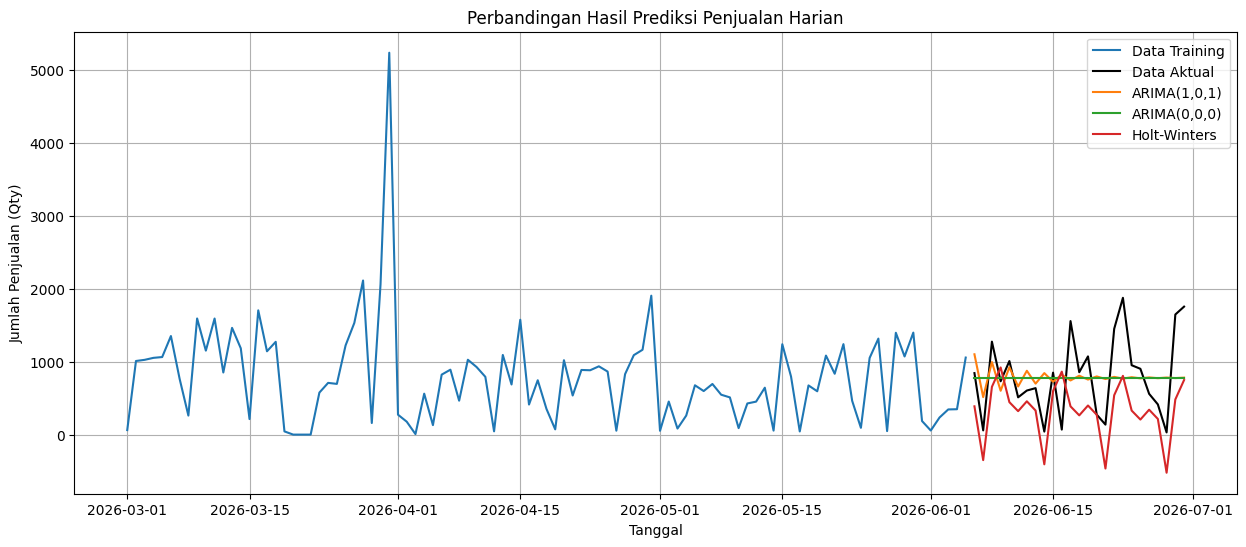

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(train.index, train,
         label="Data Training")

plt.plot(test.index, test,
         label="Data Aktual", color="black")

plt.plot(pred_arima_101.index, pred_arima_101,
         label="ARIMA(1,0,1)")

plt.plot(pred_arima_000.index, pred_arima_000,
         label="ARIMA(0,0,0)")

plt.plot(pred_hw.index, pred_hw,
         label="Holt-Winters")

plt.title("Perbandingan Hasil Prediksi Penjualan Harian")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan (Qty)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
model_terbaik = tabel_evaluasi.loc[
    tabel_evaluasi["RMSE"].idxmin()
]

print("Model terbaik berdasarkan RMSE:")
print(model_terbaik)

Model terbaik berdasarkan RMSE:
Model        ARIMA(1,0,1)
MAE            437.550473
RMSE           539.914345
sMAPE (%)       65.191969
Name: 0, dtype: object
